# 01 - Standard Datasheet Curves Extraction (IRFS7730PBF)

Extracts and plots the working datasheet studies from the vendor SPICE model
`SpiceModels/irfs7730pbf.spi` (subcircuit `irfb_s_sl7730pbf`, pins 1=Drain, 2=Gate, 3=Source):

| # | Study | Source |
|---|---|---|
| 1 | Output Characteristics - Id vs Vds family | `StaticSweepTestbench.run_output_characteristics` |
| 2 | Transfer Characteristic - Id vs Vgs | `StaticSweepTestbench.run_transfer_characteristics` |
| 3 | On-State Resistance - Rds(on) vs Id | `StaticSweepTestbench.run_rds_on` |
| 4 | Capacitances - Ciss/Coss/Crss vs Vds | `CapacitanceTestbench.run` |
| 5 | Body Diode - Isd vs Vsd | `StaticSweepTestbench.run_body_diode` |
| 6 | Gate Threshold Voltage - Vgs(th) @ Id=250uA | `StaticSweepTestbench.run_threshold_voltage` |

**Gate charge study is excluded**: the MODPEX sense-and-mirror network inside this vendor model
becomes unstable under constant-current gate drive. See `gate_charge_error_analysis.md`.

Style: publication-quality serif/STIX typography, boxed axes with inward minor ticks on all
four sides, dashed grid, 300 dpi, EAST-outside legend sized from its actual width so the
axes area stays dominant. Plots are displayed inline (`plt.show()`), never saved.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt

from common.plotting import setup_style, plot_curves
from simulation.testbenches.static_sweep import StaticSweepTestbench
from simulation.testbenches.capacitance import CapacitanceTestbench

LIB = Path(r"C:\Users\GNKRISHNAN\Documents\GitHub\PieceSpice\SpiceModels\irfs7730pbf.spi")
SUBCKT = "irfb_s_sl7730pbf"
TITLE = "IRFS7730PBF"

setup_style()
static = StaticSweepTestbench()

## Study 1 - Output Characteristics (Id vs Vds family)
Datasheet gate curves: Vgs = 4.5 / 5 / 6 / 8 / 10 V.

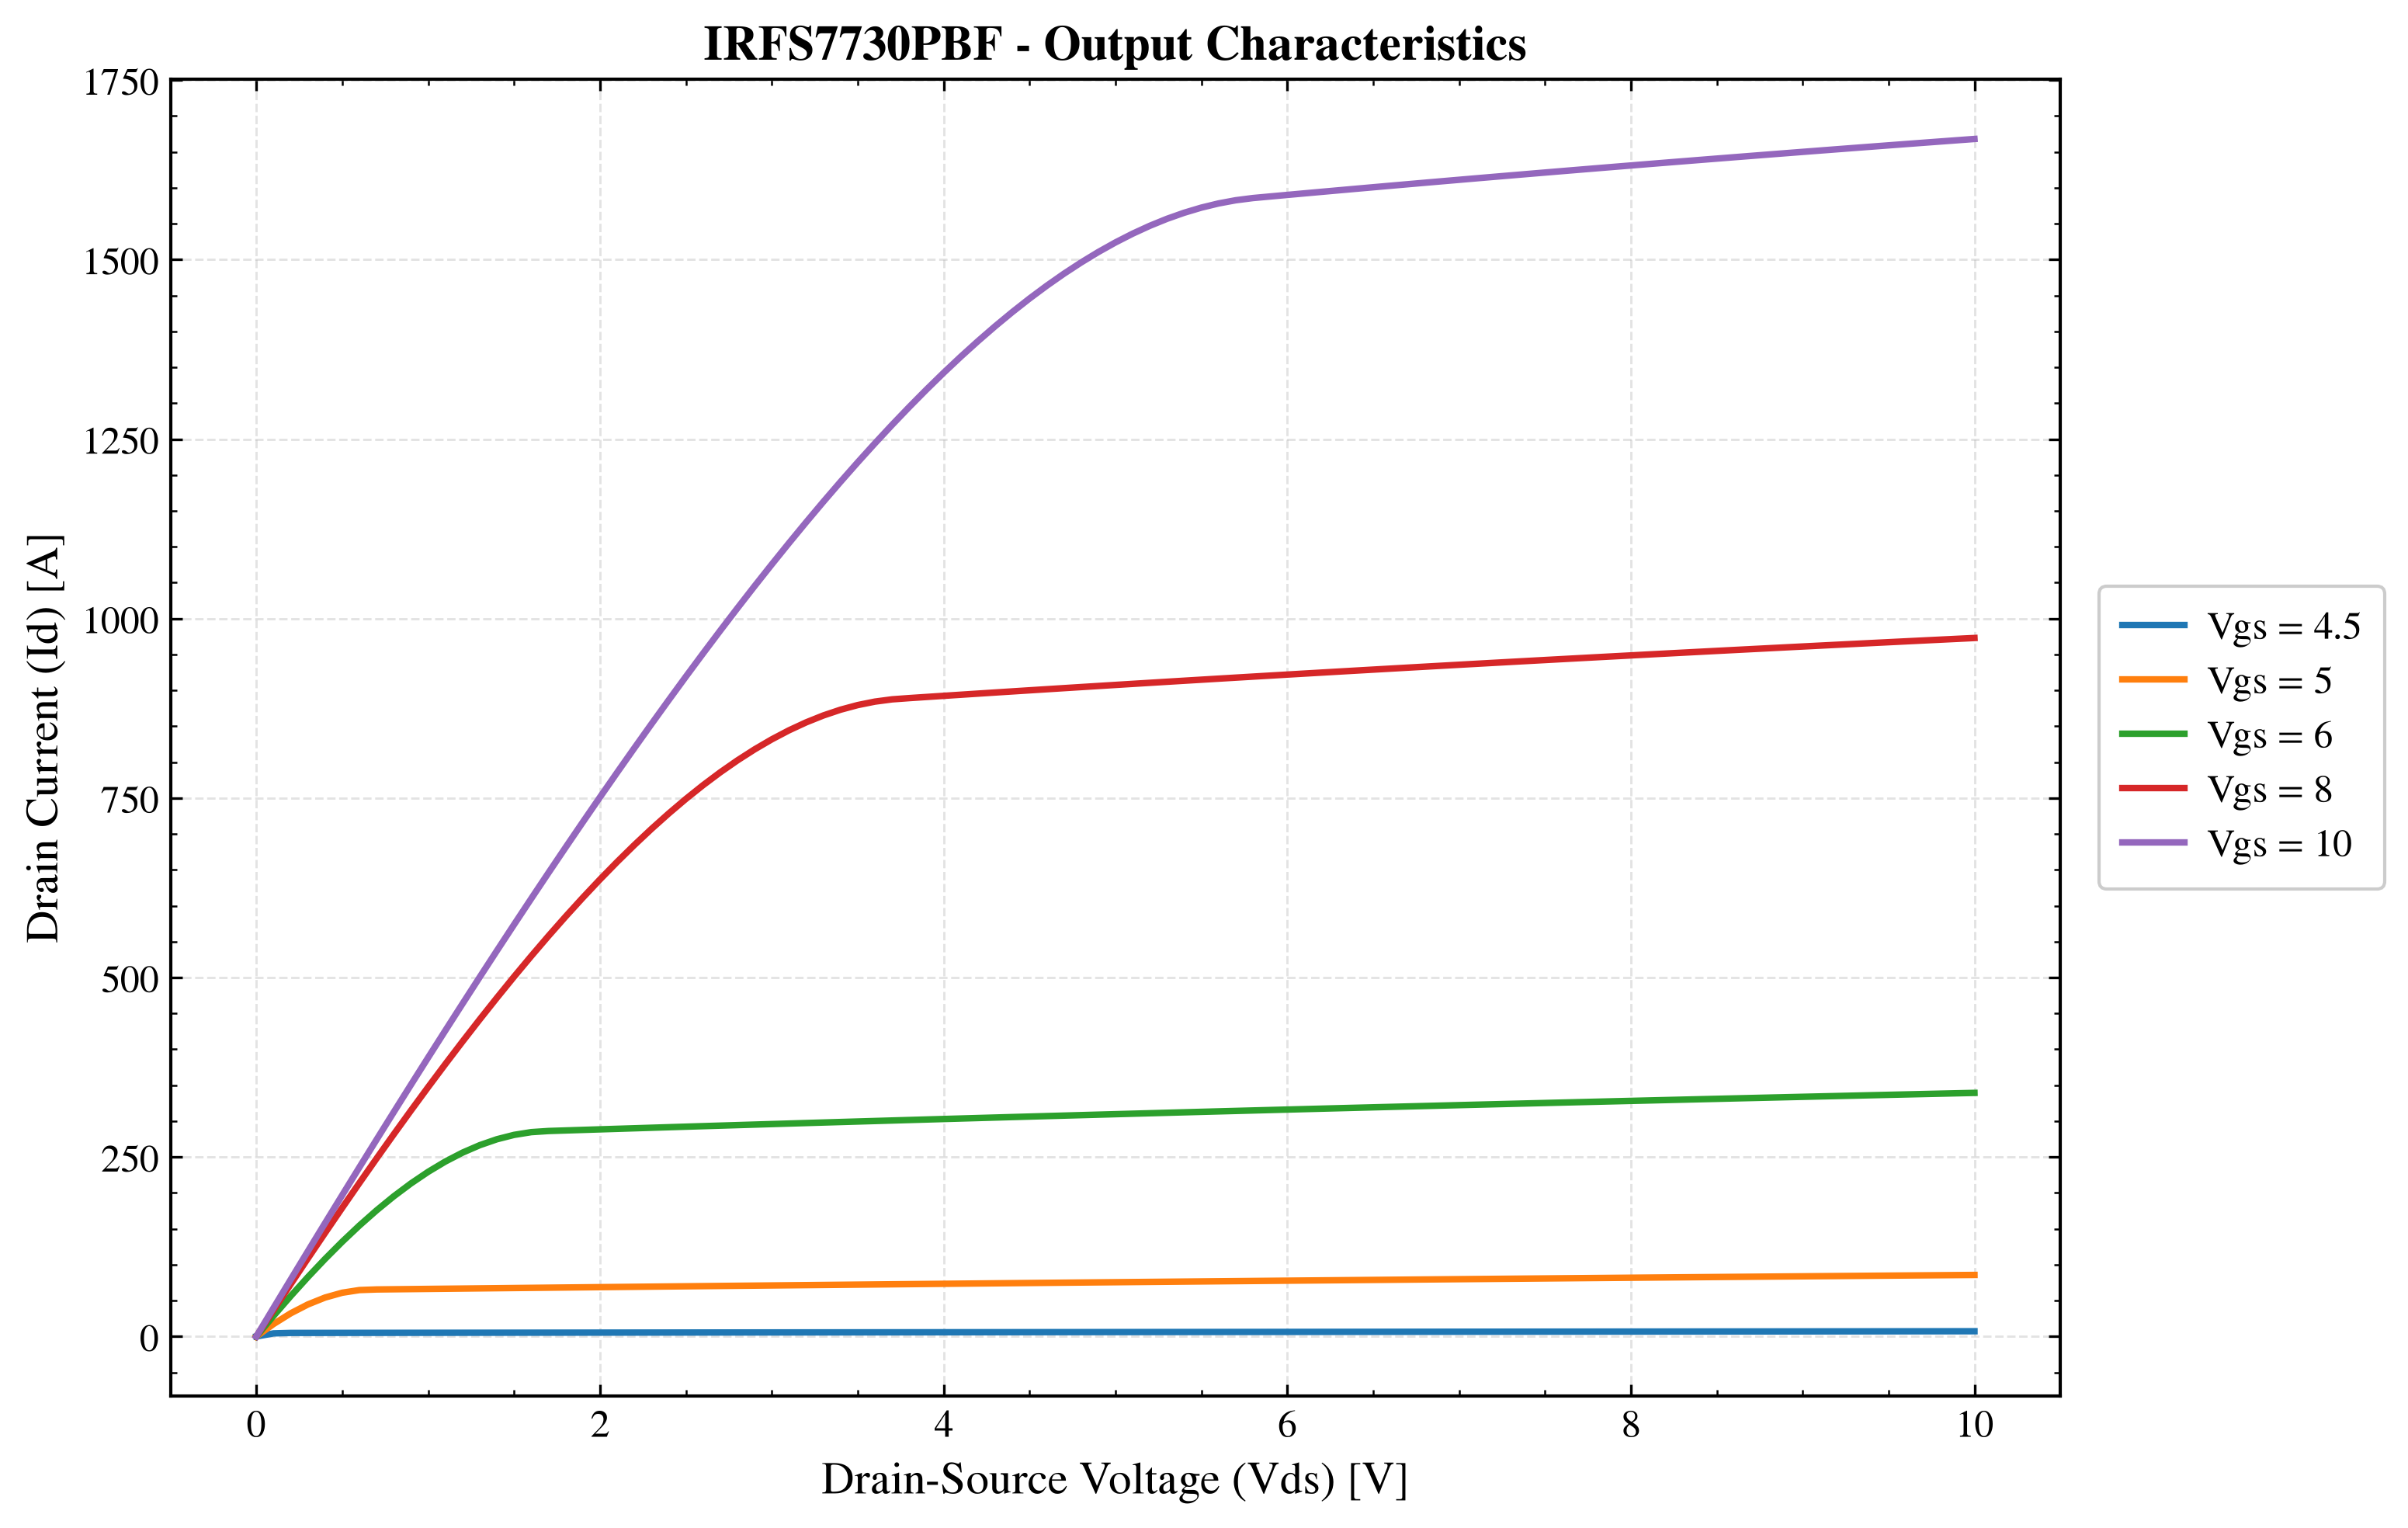

In [2]:
output_curves = static.run_output_characteristics(
    LIB, SUBCKT,
    vgs_list=[4.5, 5.0, 6.0, 8.0, 10.0],
    vds_max=10.0, vds_points=101,
)
plot_curves(output_curves, f"{TITLE} - Output Characteristics")
plt.show()

## Study 2 - Transfer Characteristic (Id vs Vgs at Vds = 10 V)

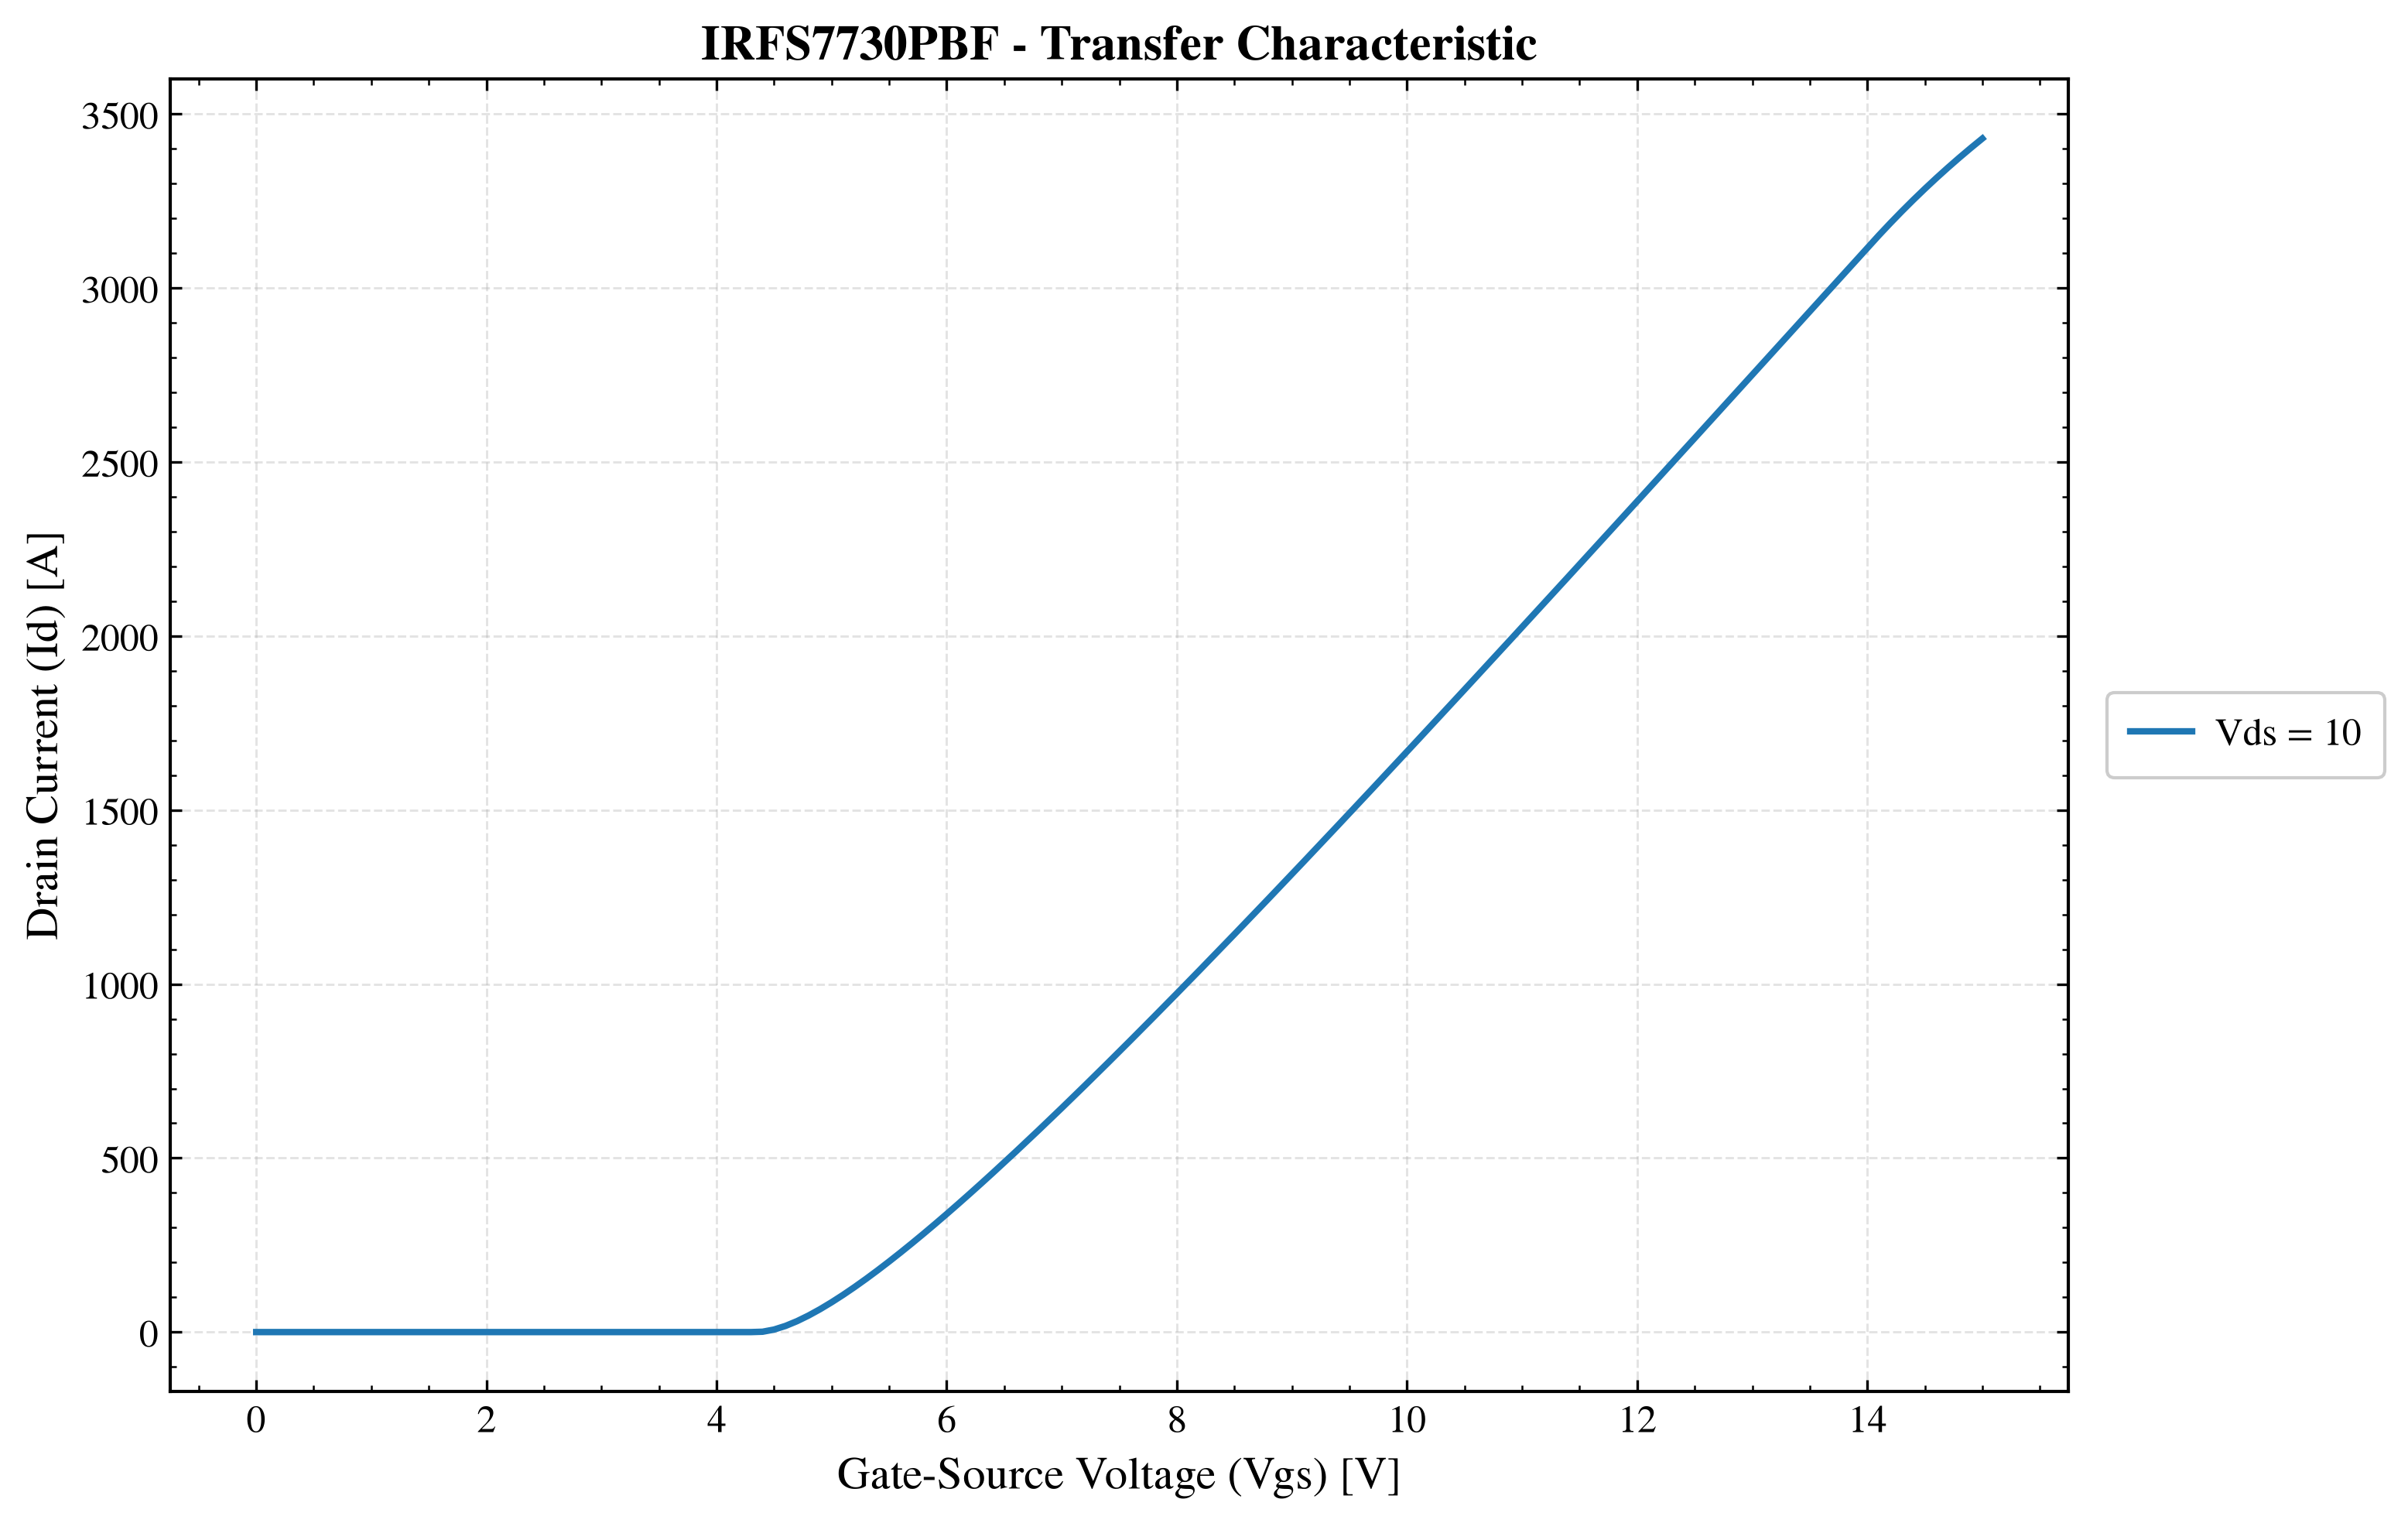

In [3]:
transfer_curve = static.run_transfer_characteristics(
    LIB, SUBCKT, vds_fixed=10.0, vgs_max=15.0, vgs_points=151,
)
plot_curves([transfer_curve], f"{TITLE} - Transfer Characteristic")
plt.show()

## Study 3 - On-State Resistance (Rds(on) vs Id at Vgs = 10 V)

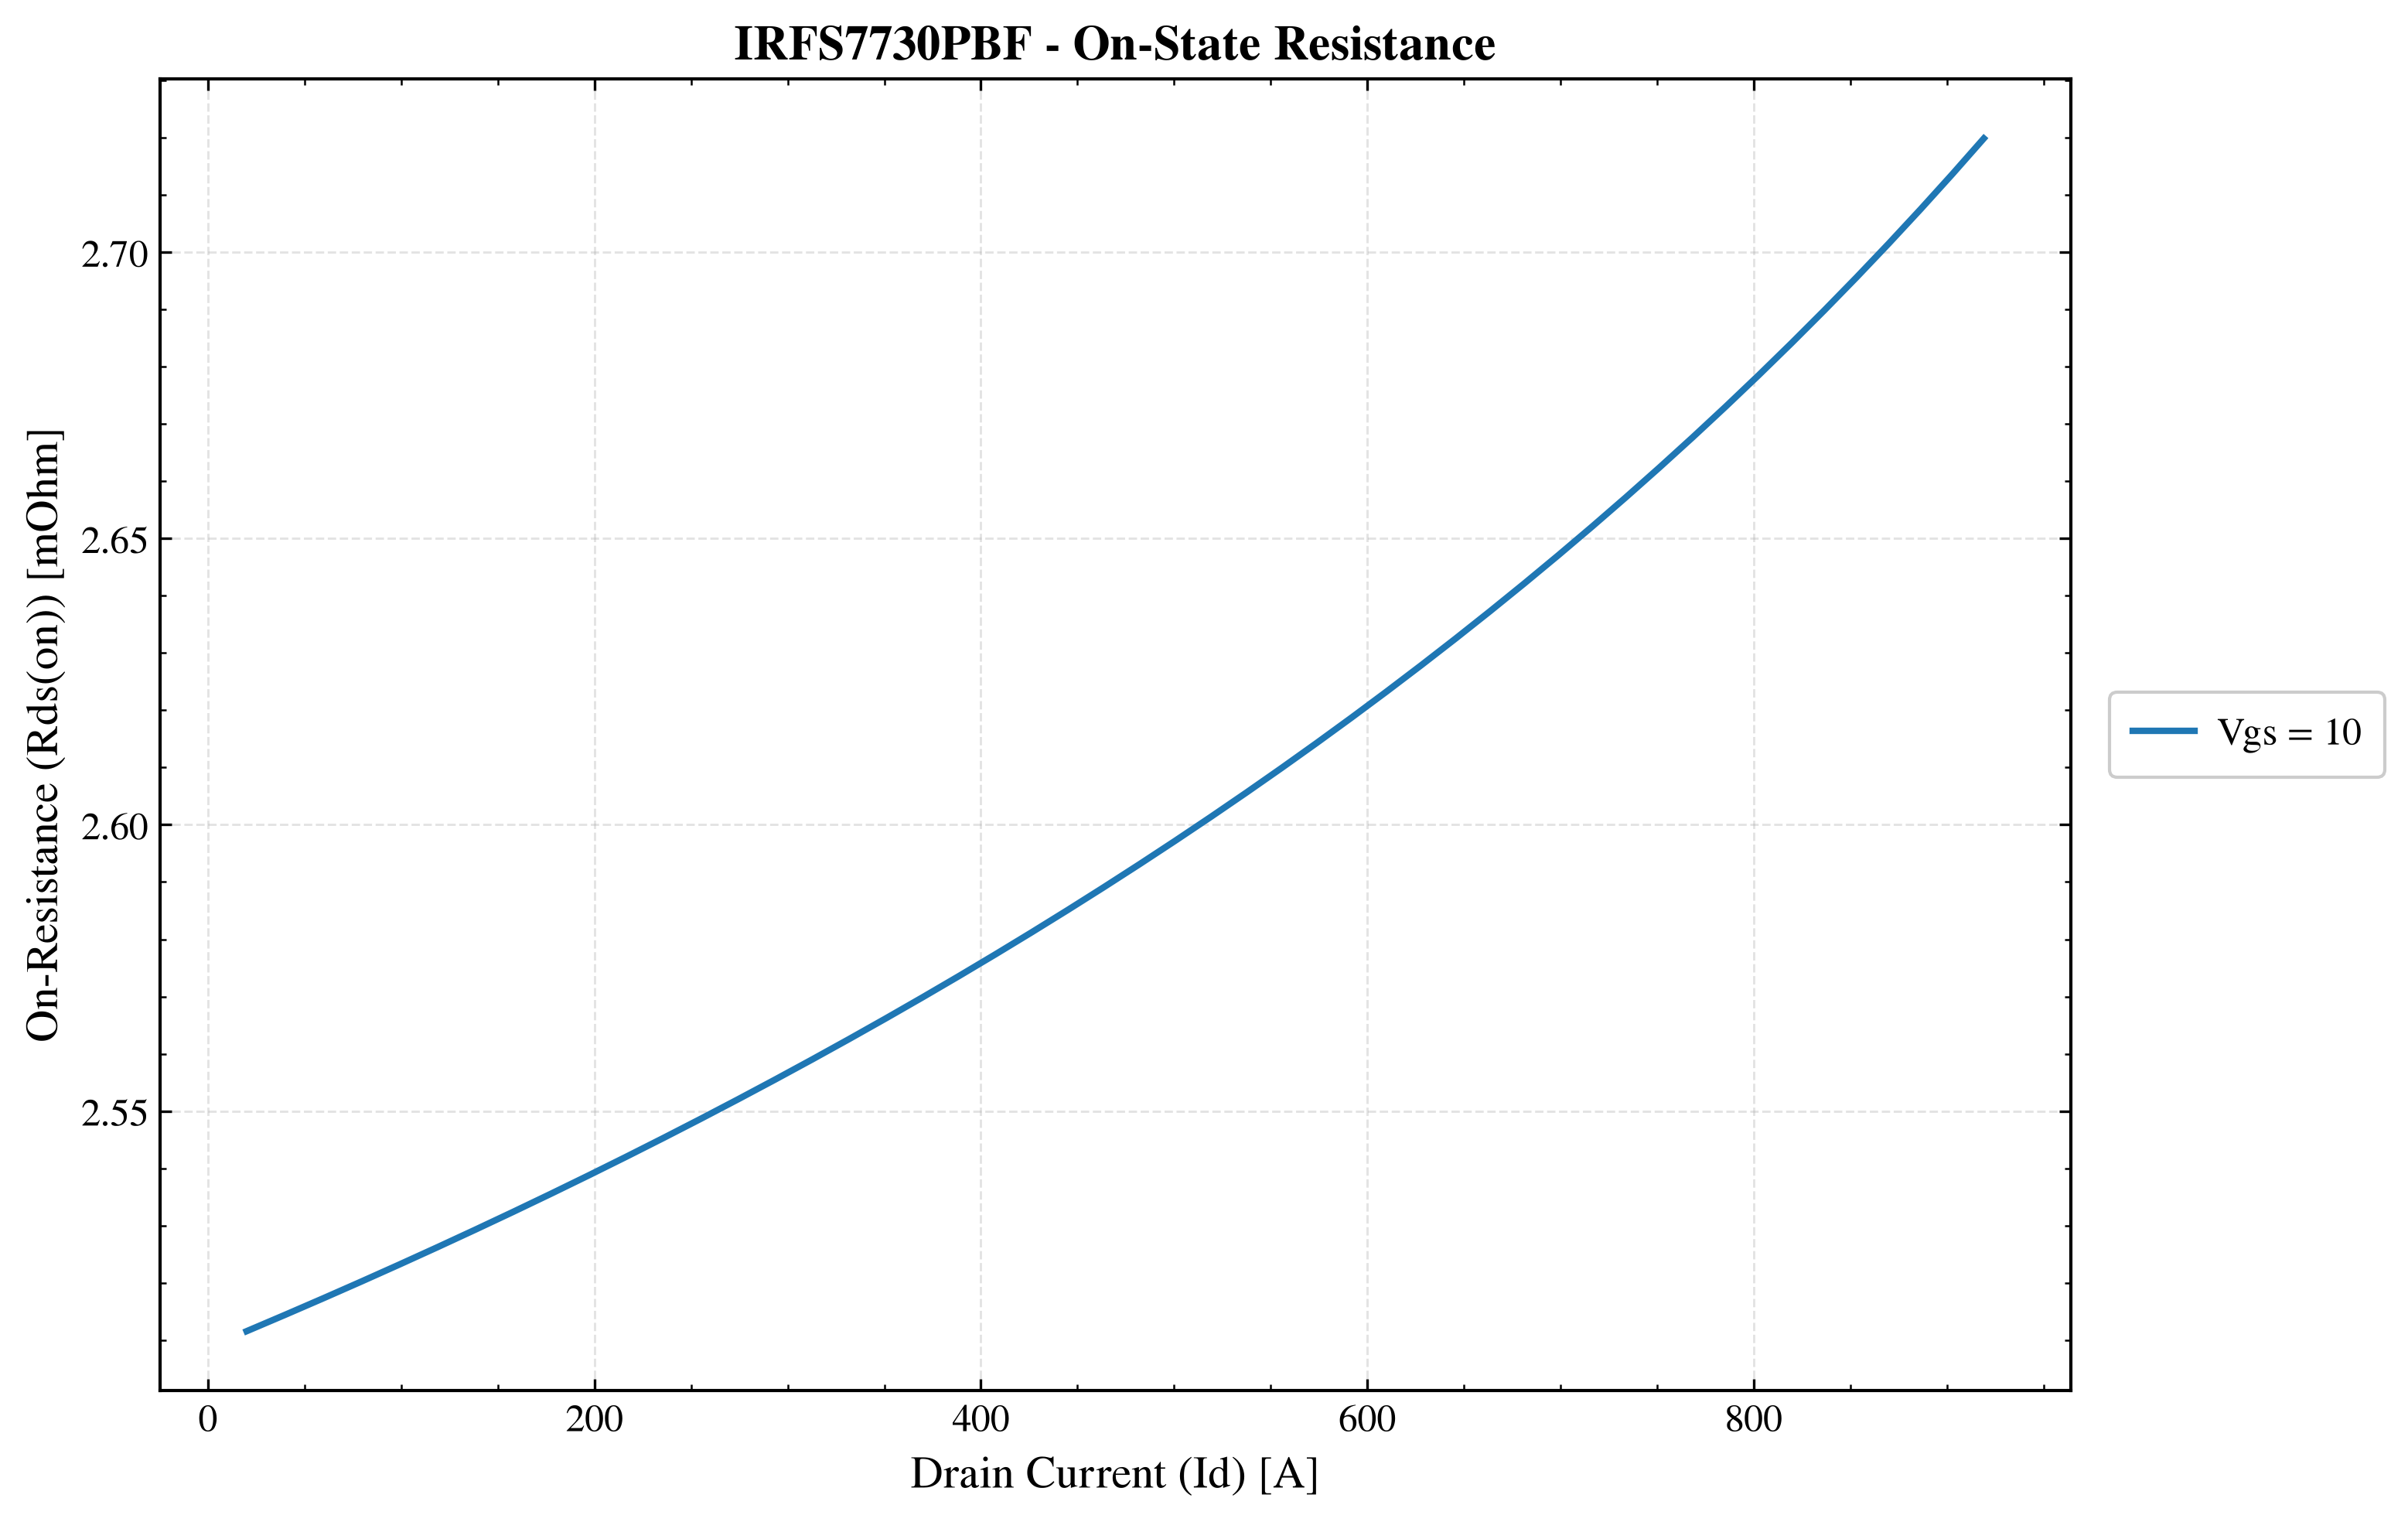

In [4]:
rds_curve = static.run_rds_on(LIB, SUBCKT, vgs=10.0, vds_max=2.5, vds_points=51)
plot_curves([rds_curve], f"{TITLE} - On-State Resistance")
plt.show()

## Study 4 - Capacitances vs Vds
Small-signal AC method at 1 MHz; log sweep 0.1-60 V (model breakdown is 75 V).

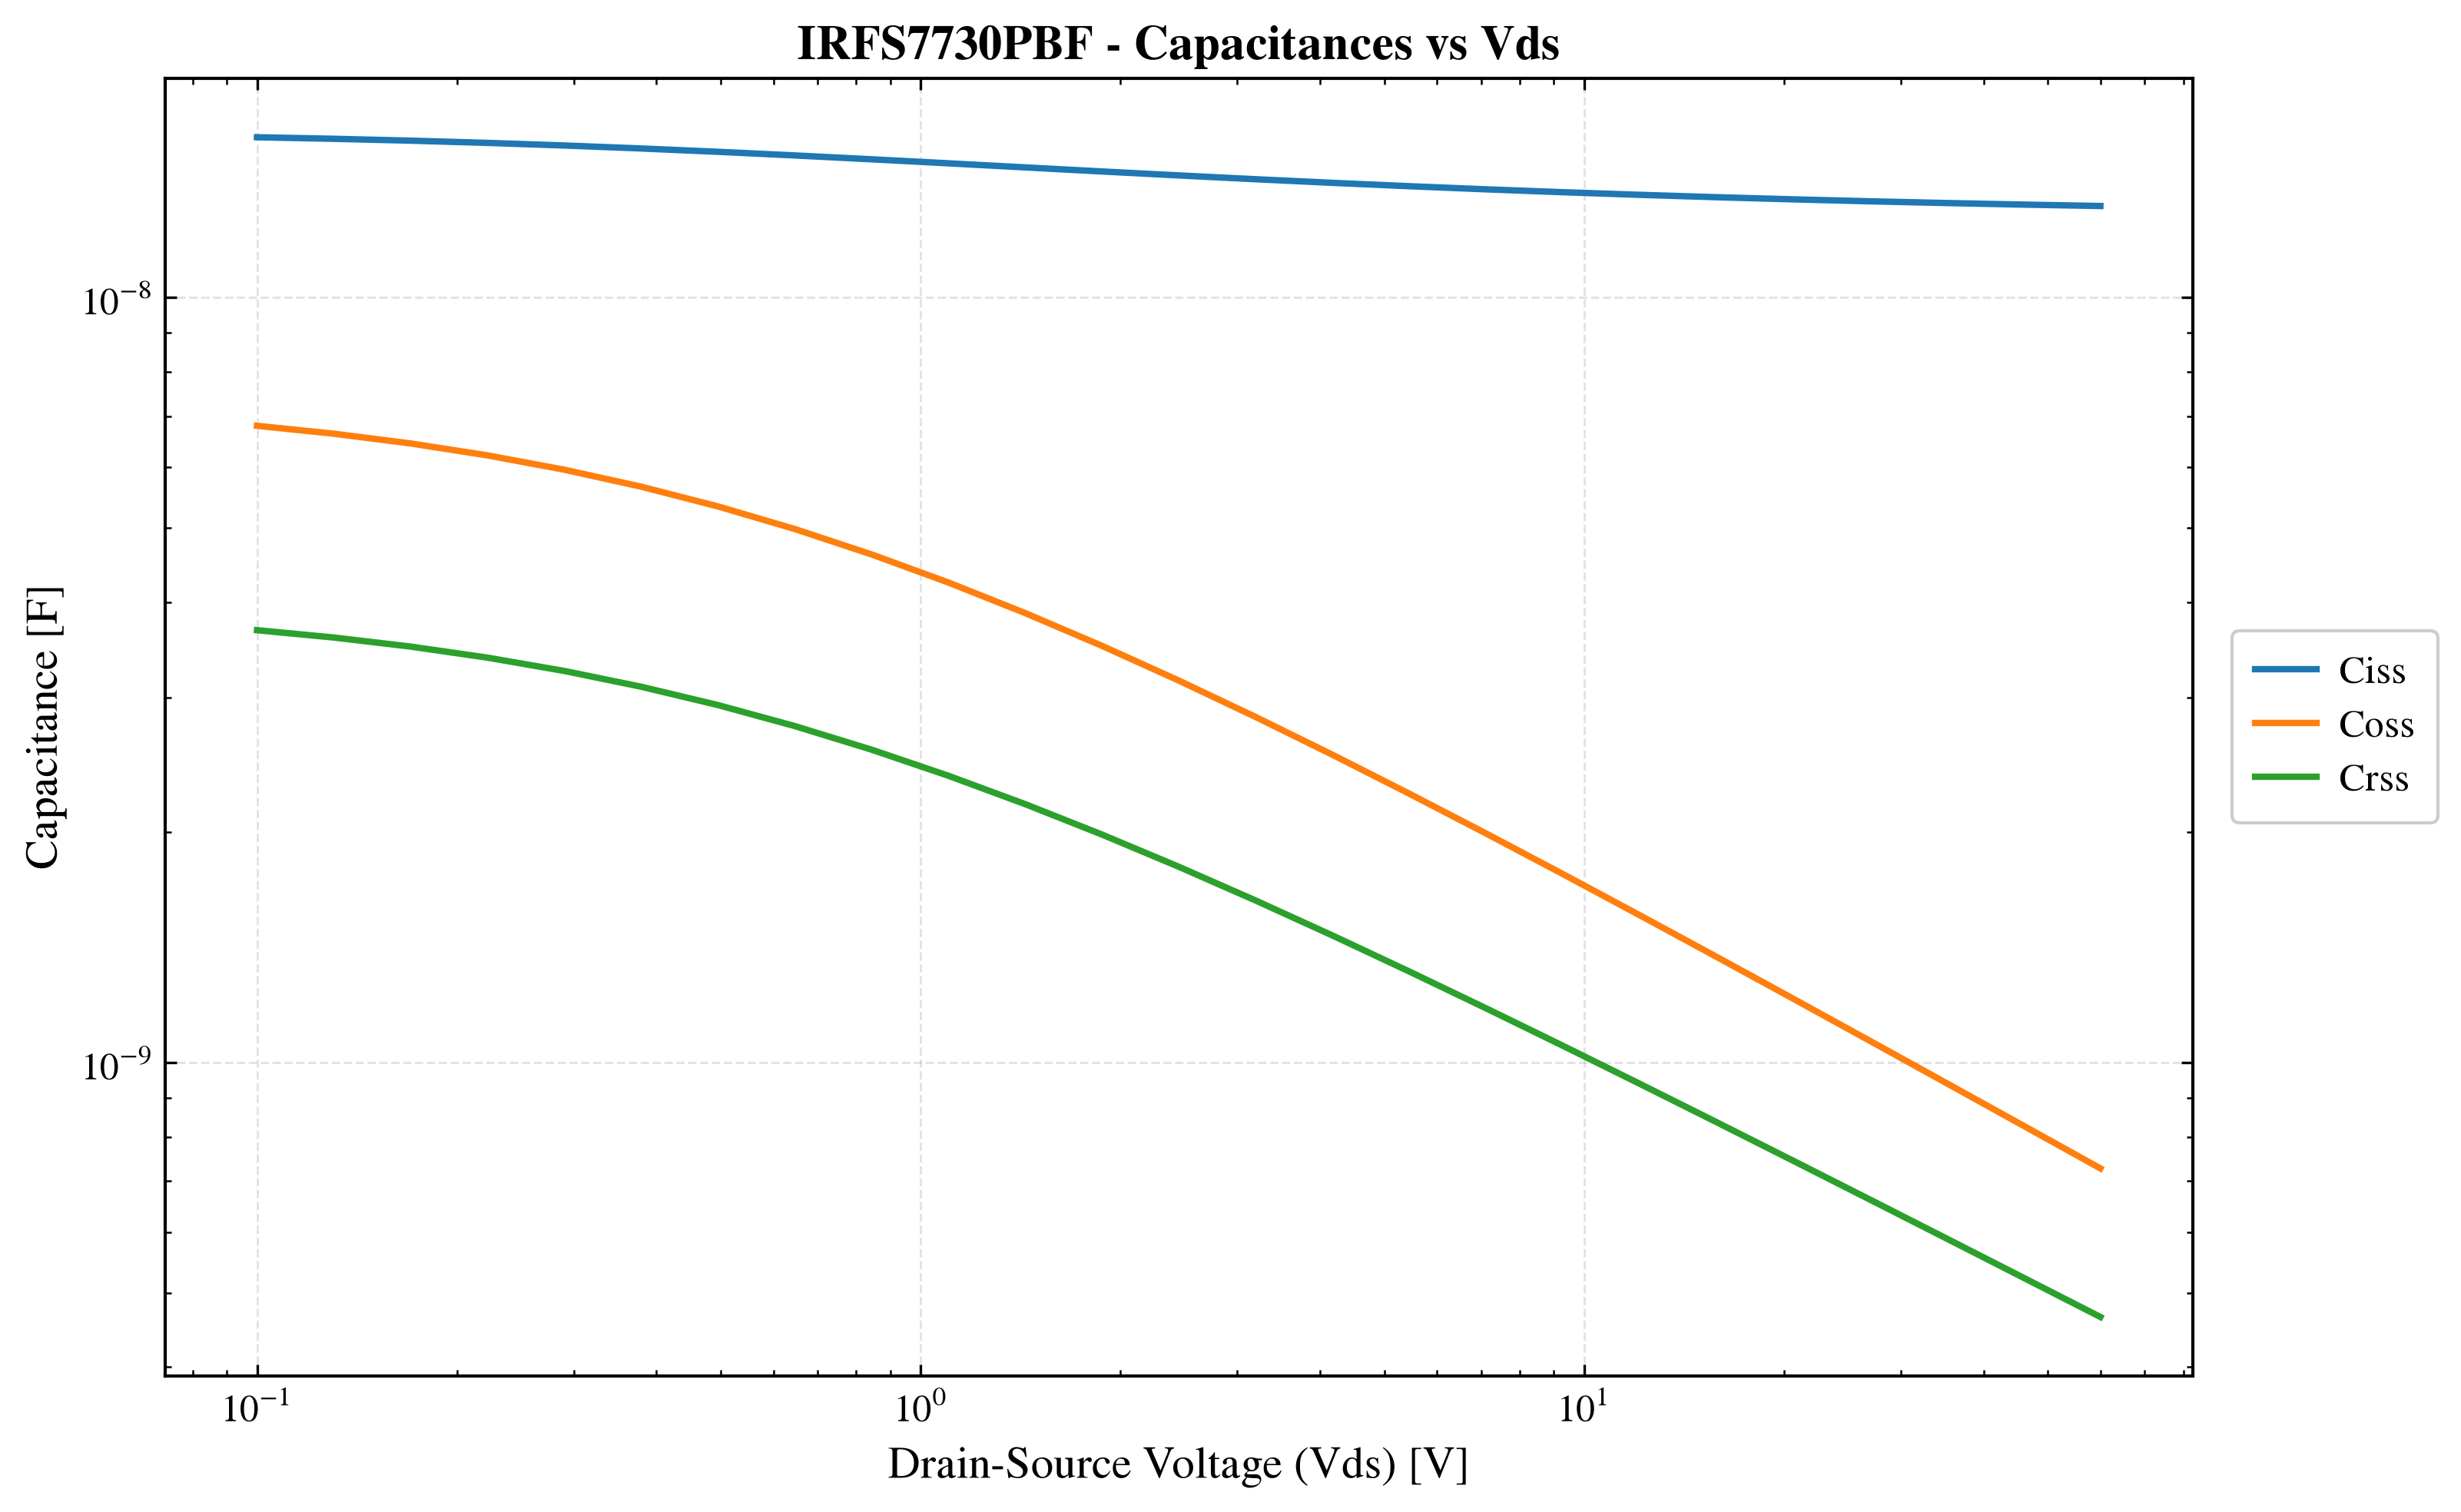

In [5]:
cap_curves = CapacitanceTestbench().run(LIB, SUBCKT, vds_min=0.1, vds_max=60.0, points=25)
fig_caps, ax_caps = plot_curves(
    cap_curves, f"{TITLE} - Capacitances vs Vds", x_log=True, y_log=True,
)
ax_caps.set_ylabel("Capacitance [F]")
plt.show()

## Study 5 - Body Diode Forward Characteristic (gate off)
Voltage-driven, capped at 1 V to stay clear of the diode exponential divergence.

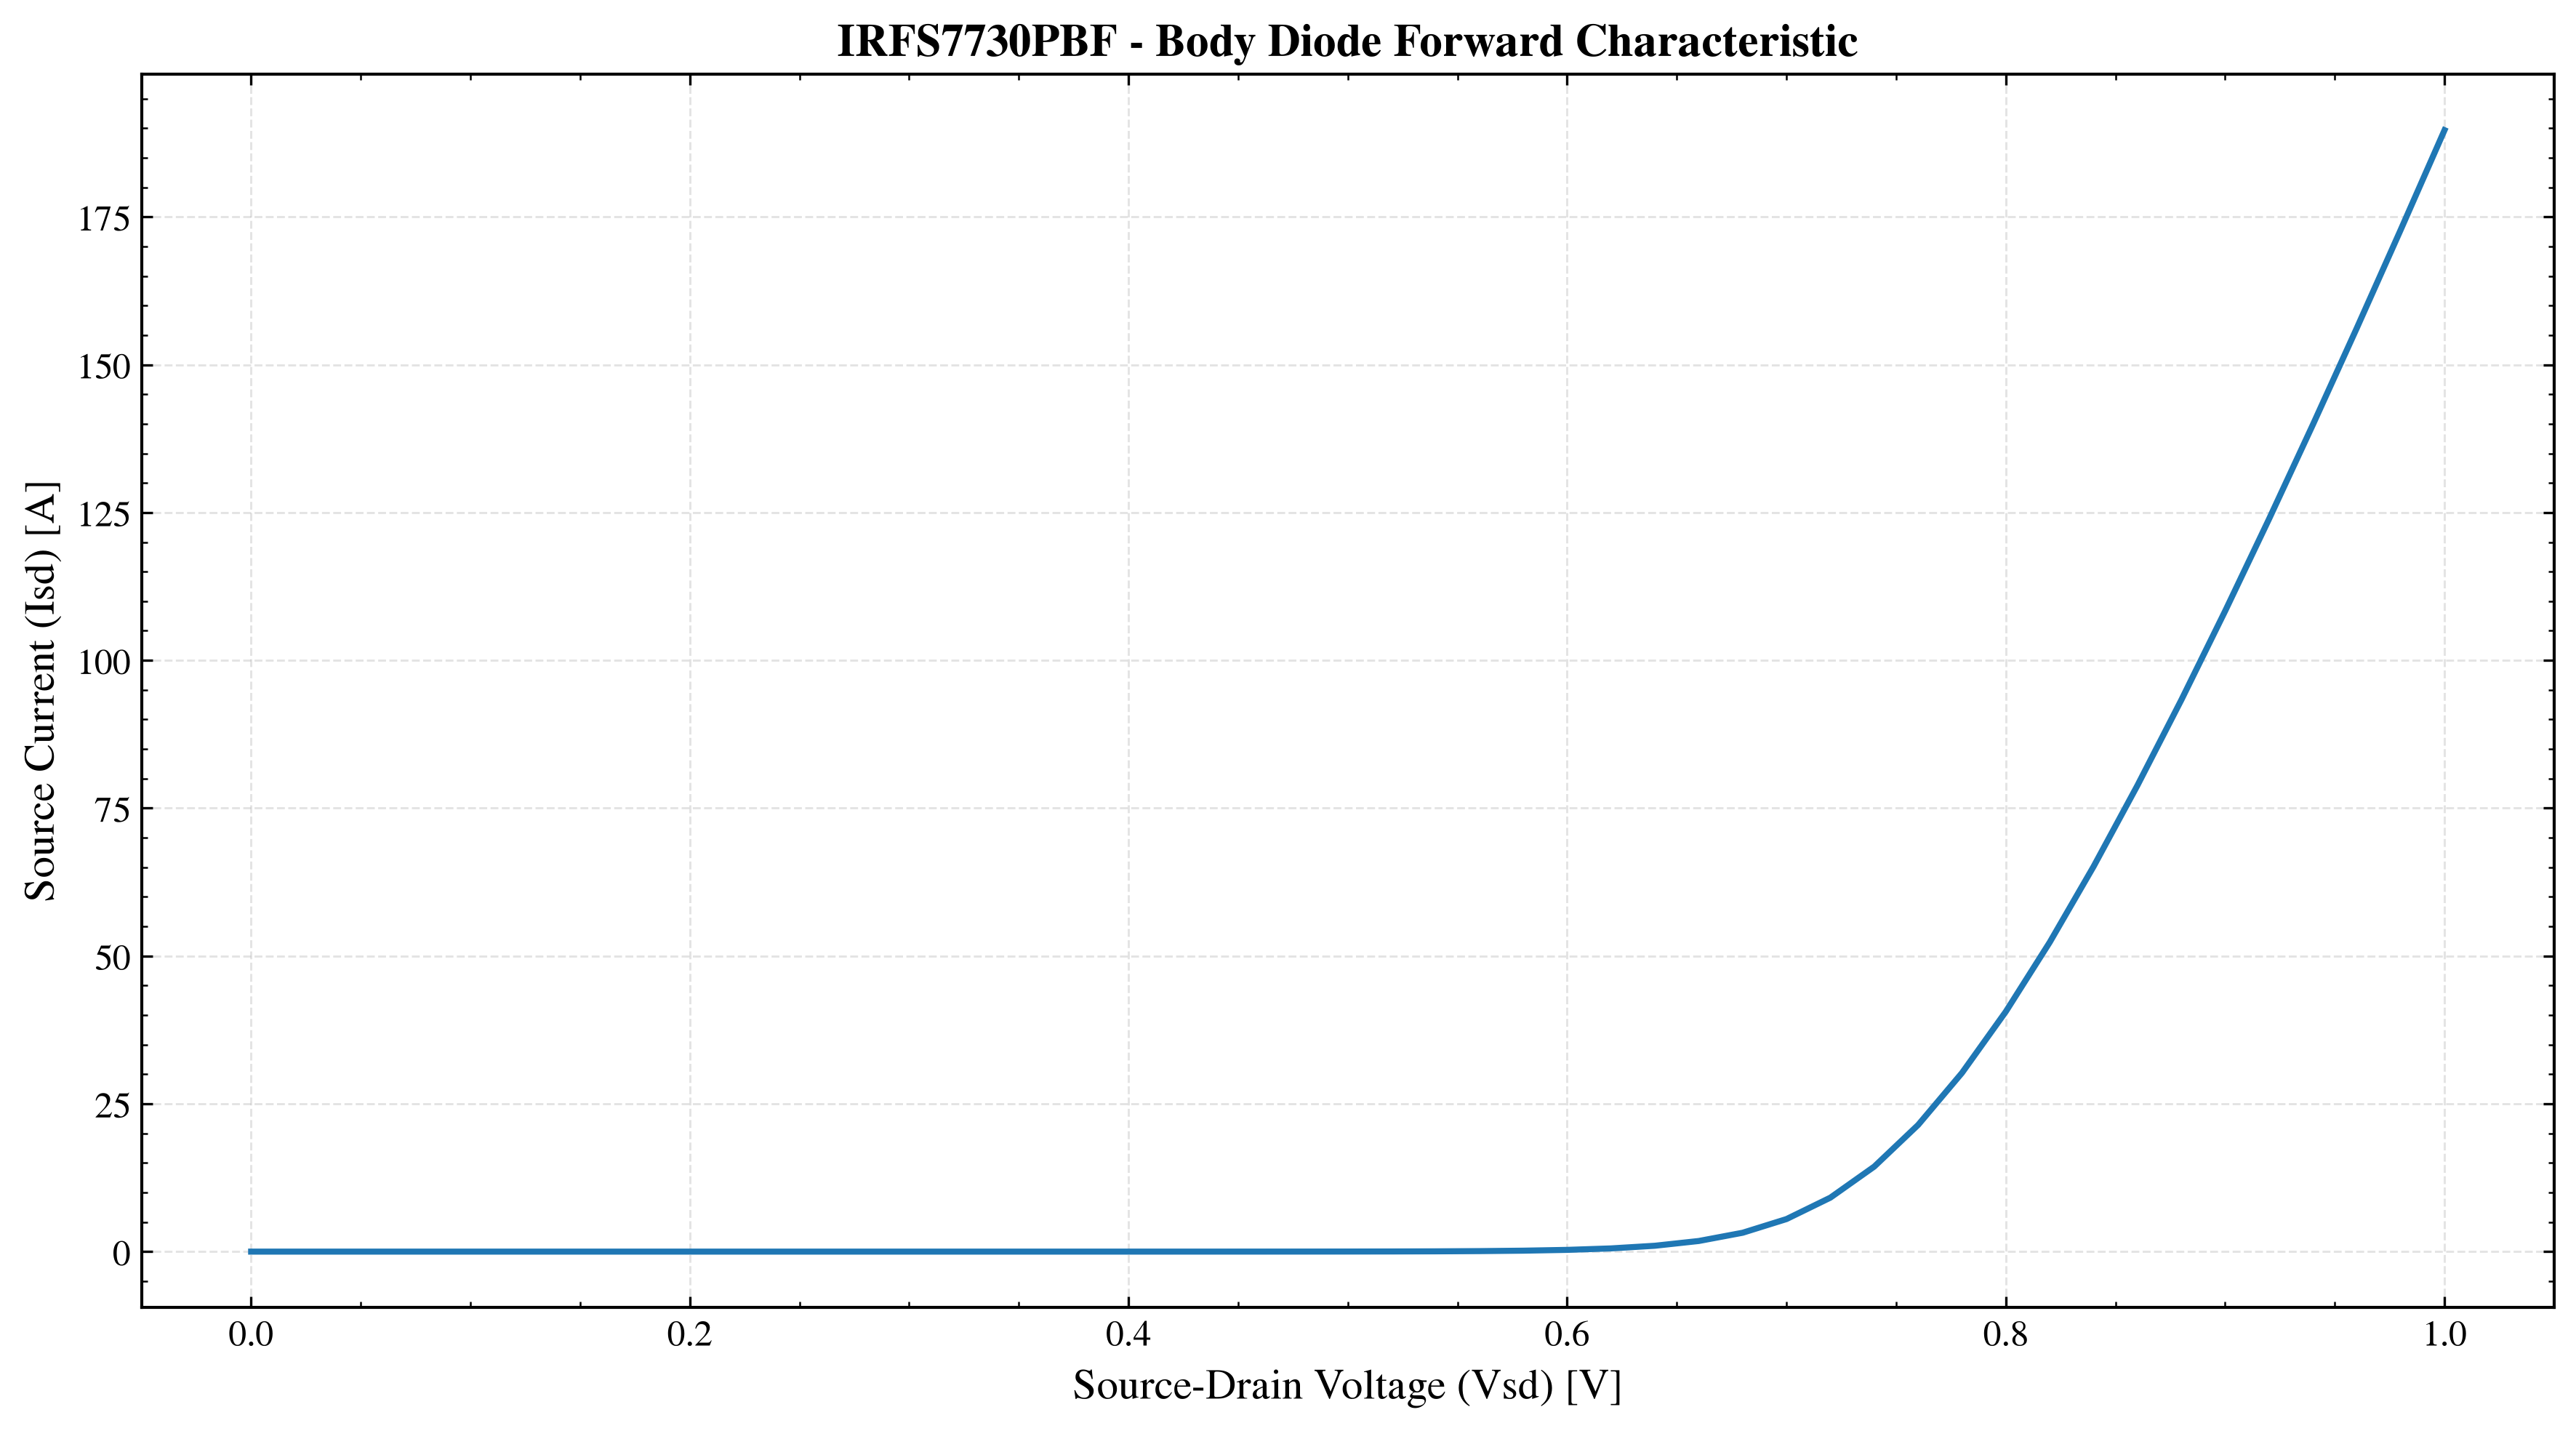

In [6]:
diode_curve = static.run_body_diode(LIB, SUBCKT, vsd_max=1.0, points=51)
plot_curves([diode_curve], f"{TITLE} - Body Diode Forward Characteristic")
plt.show()

## Study 6 - Gate Threshold Voltage (constant-current method)

Datasheet convention: **gate shorted to drain (`Vds = Vgs`)**, sweep, interpolate
`Vgs` at **Id = 250 uA**.

> **Known model limitation:** this vendor macromodel uses a LEVEL=1 MOSFET with a hard
> threshold (no subthreshold conduction). The extracted value reflects the fitted
> `VTO = 4.346 V`, which matches the mid-current transfer characteristic but sits above
> the datasheet spec band **VGS(th) = 2.1-3.7 V** (`VDS = VGS, ID = 250 uA`). The real
> device's subthreshold physics cannot be represented by this LEVEL=1 model file; this is
> a vendor-model artifact, not an extraction error.

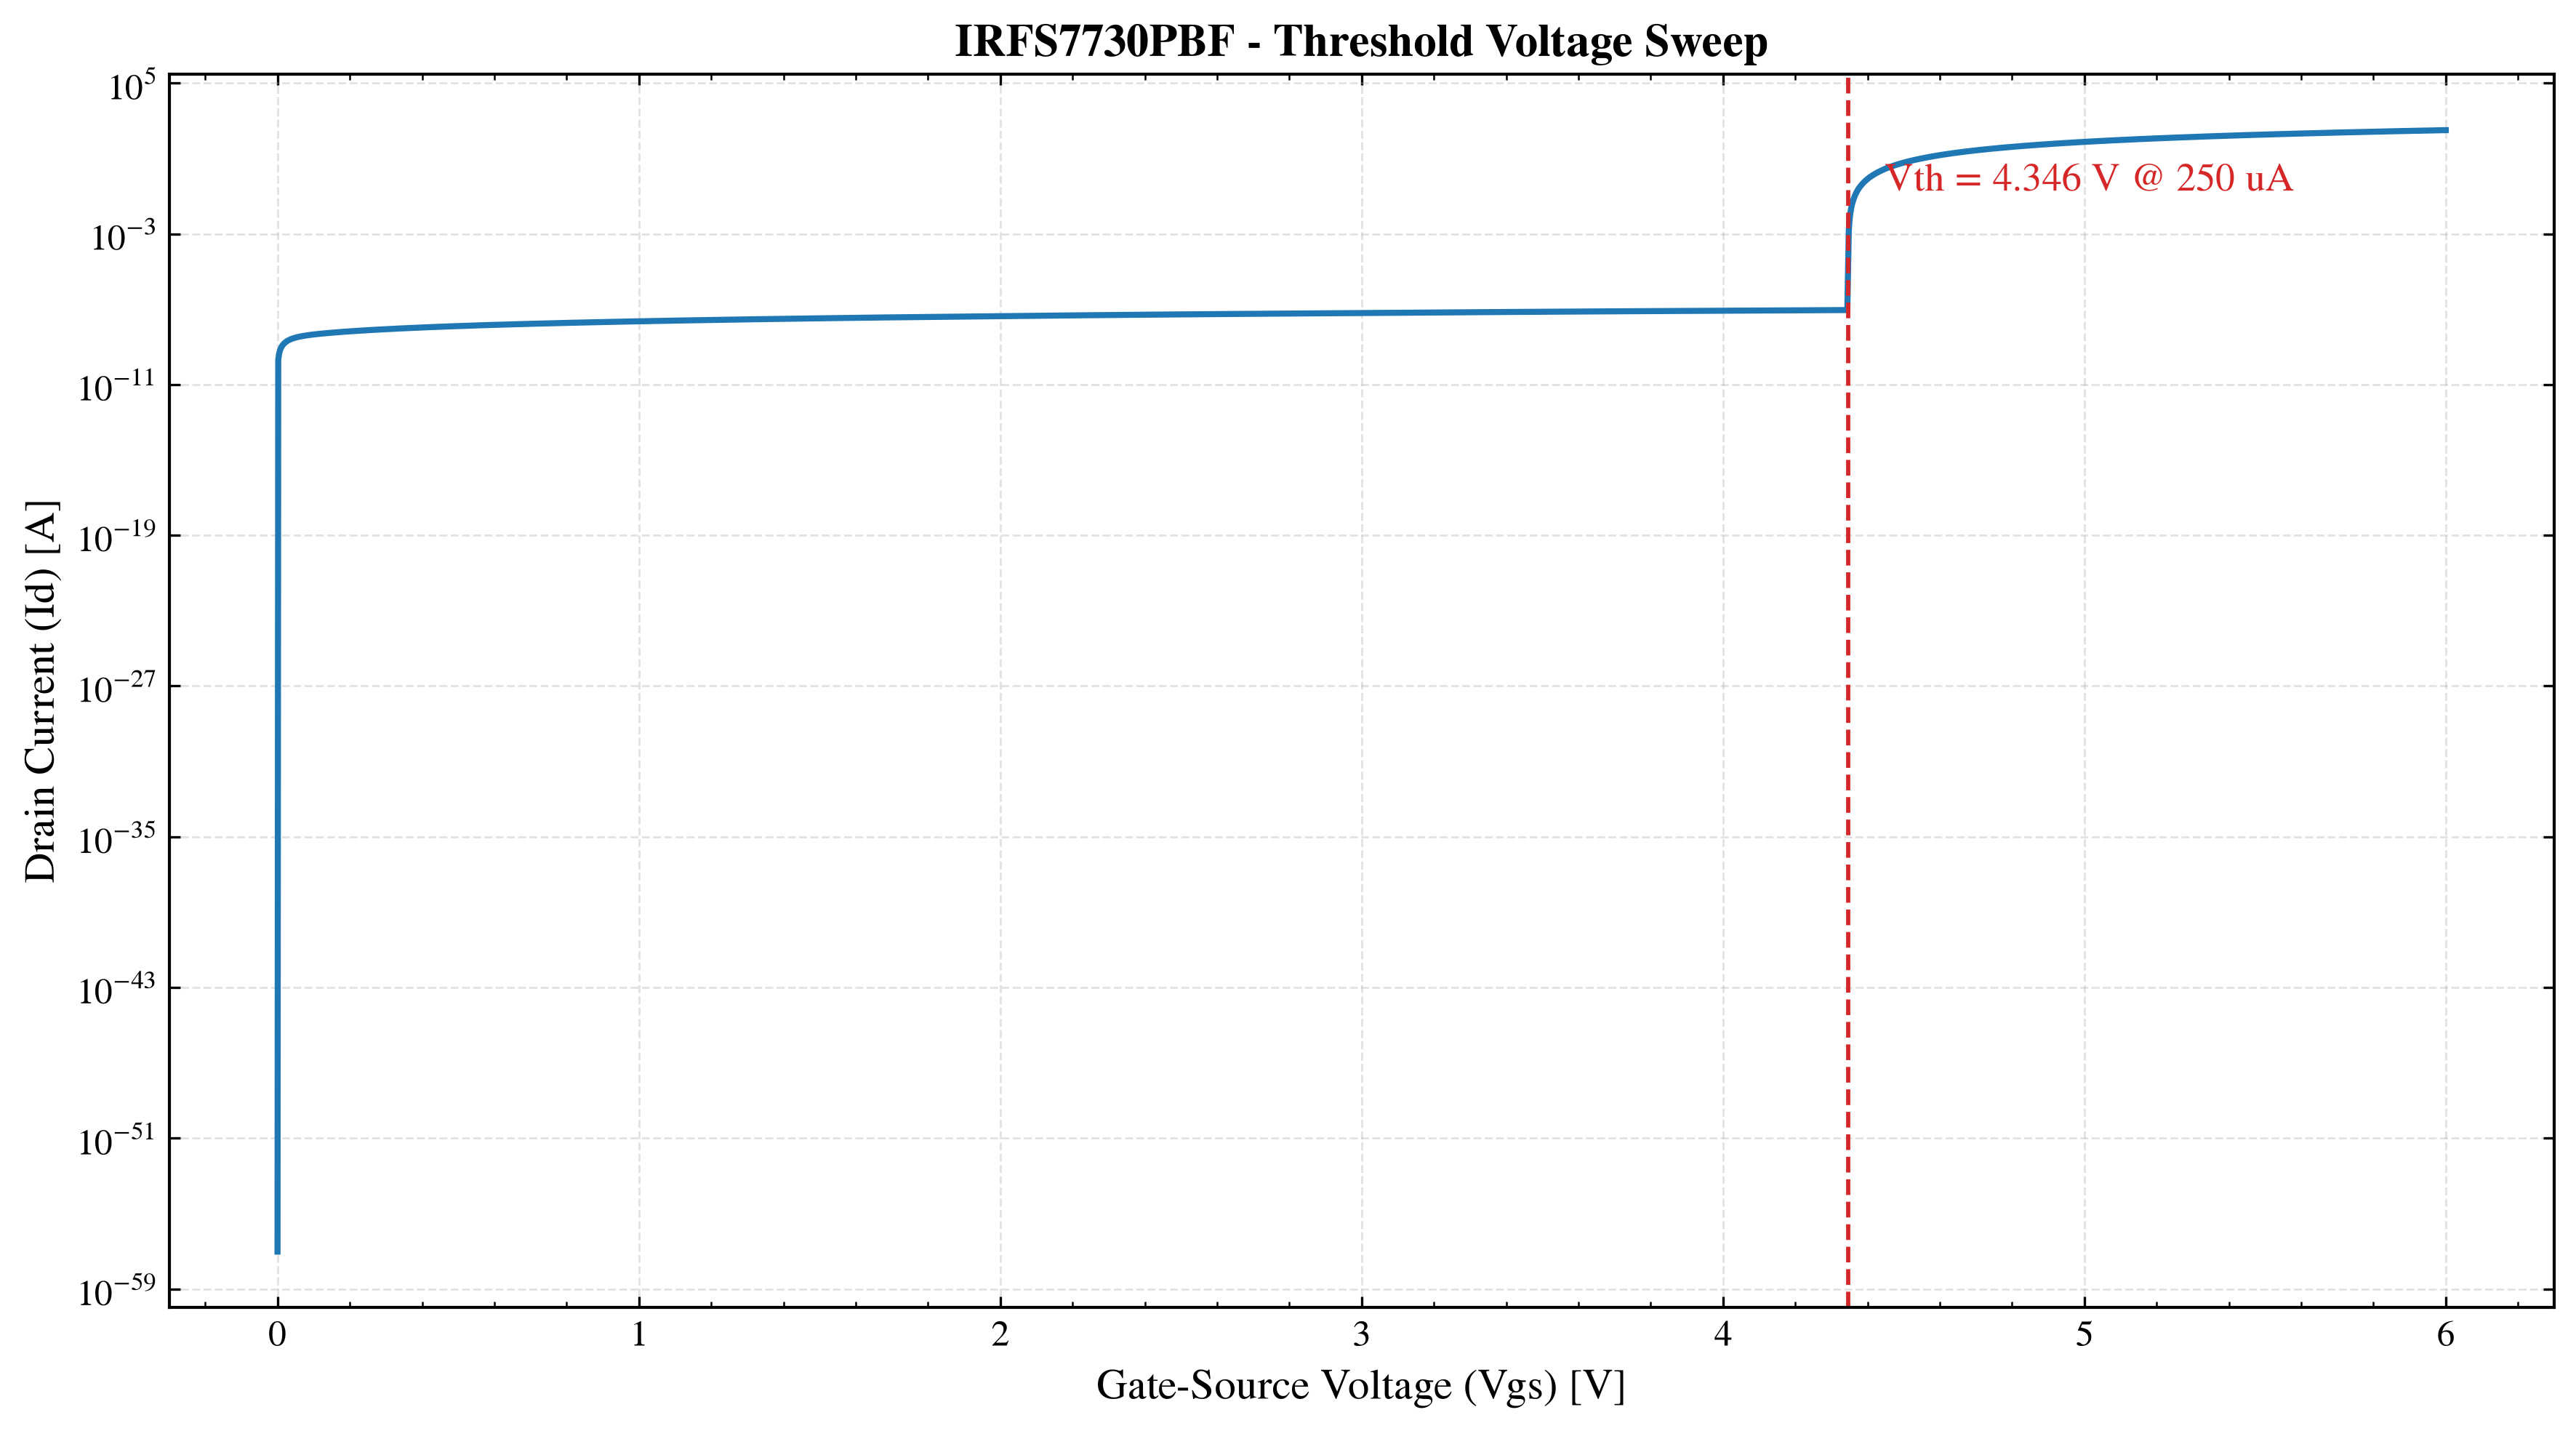

In [7]:
vth_curve, v_th = static.run_threshold_voltage(LIB, SUBCKT, i_target=250e-6, v_max=6.0)
fig_vth, ax_vth = plot_curves(
    [vth_curve], f"{TITLE} - Threshold Voltage Sweep", y_log=True,
)
ax_vth.axvline(v_th, color="tab:red", linestyle="--", linewidth=1.4)
ax_vth.annotate(
    f"Vth = {v_th:.3f} V @ 250 uA",
    xy=(v_th, 250e-6), xytext=(12, 18), textcoords="offset points",
    fontsize=13, color="tab:red",
)
plt.show()

## Extracted Datasheet Figures

In [8]:
import numpy as np

rx, ry = rds_curve.to_numpy()

print(f"Rds(on) @ Vgs=10V, Id=50A : {np.interp(50.0, rx, ry):.2f} mOhm")
print(f"Vgs(th) constant-current  : {v_th:.3f} V   (model artifact, see note above)")
for c in cap_curves:
    print(f"{c.name} @ Vds=40V            : {np.interp(40.0, c.x_data, c.y_data) * 1e9:.2f} nF")
dx, dy = diode_curve.to_numpy()
print(f"Body diode Vsd @ Isd=50A  : {np.interp(50.0, dy, dx) * 1e3:.1f} mV")

Rds(on) @ Vgs=10V, Id=50A : 2.52 mOhm
Vgs(th) constant-current  : 4.346 V   (model artifact, see note above)
Ciss @ Vds=40V            : 13.26 nF
Coss @ Vds=40V            : 0.89 nF
Crss @ Vds=40V            : 0.56 nF
Body diode Vsd @ Isd=50A  : 816.1 mV
